# Part 1: Sign Language 'Word' detection using LSTM and Mediapipe
## !!! Part 2 of this project is in the other jupyter notebook, which has the ASL to English translation code !!!
# American Sign Language Detection using Mediapipe and LSTM, 
# ASL to English Translation using T5 text-to-text Transformer

## !!! All the commented sections in this code, are the attempts we made for optimizing our results, or for debugging !!!

# Code:

# 1. Importing Dependencies

In [2]:
import cv2
import numpy as np
import os
from matplotlib import pyplot as plt
import time
import mediapipe as mp
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 2. Keypoints using MP Holistic

In [5]:
mp_holistic = mp.solutions.holistic # Holistic model
mp_drawing = mp.solutions.drawing_utils # Drawing utilities

In [7]:
def mediapipe_detection(image, model):
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # COLOR CONVERSION BGR 2 RGB
    image.flags.writeable = False                  # Image is no longer writeable
    results = model.process(image)                 # Make prediction
    image.flags.writeable = True                   # Image is now writeable 
    image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR) # COLOR COVERSION RGB 2 BGR
    return image, results

In [9]:
def draw_landmarks(image, results):
    mp_drawing.draw_landmarks(image, results.face_landmarks, mp_holistic.FACEMESH_TESSELATION) # Draw face connections
    mp_drawing.draw_landmarks(image, results.pose_landmarks, mp_holistic.POSE_CONNECTIONS) # Draw pose connections
    mp_drawing.draw_landmarks(image, results.left_hand_landmarks, mp_holistic.HAND_CONNECTIONS) # Draw left hand connections
    mp_drawing.draw_landmarks(image, results.right_hand_landmarks, mp_holistic.HAND_CONNECTIONS) # Draw right hand connections

In [11]:
def draw_styled_landmarks(image, results):
    # Draw pose landmarks
    mp_drawing.draw_landmarks(
        image, results.pose_landmarks, mp_holistic.POSE_CONNECTIONS,
        mp_drawing.DrawingSpec(color=(80, 22, 10), thickness=2, circle_radius=4),
        mp_drawing.DrawingSpec(color=(80, 44, 121), thickness=2, circle_radius=2)
    )
    # Draw face landmarks
    mp_drawing.draw_landmarks(
        image, results.face_landmarks, mp_holistic.FACEMESH_TESSELATION,
        mp_drawing.DrawingSpec(color=(80, 110, 10), thickness=1, circle_radius=1),
        mp_drawing.DrawingSpec(color=(80, 256, 121), thickness=1, circle_radius=1)
    )
    # Draw hand landmarks
    mp_drawing.draw_landmarks(
        image, results.left_hand_landmarks, mp_holistic.HAND_CONNECTIONS,
        mp_drawing.DrawingSpec(color=(121, 22, 76), thickness=2, circle_radius=4),
        mp_drawing.DrawingSpec(color=(121, 44, 250), thickness=2, circle_radius=2)
    )
    mp_drawing.draw_landmarks(
        image, results.right_hand_landmarks, mp_holistic.HAND_CONNECTIONS,
        mp_drawing.DrawingSpec(color=(245, 117, 66), thickness=2, circle_radius=4),
        mp_drawing.DrawingSpec(color=(245, 66, 230), thickness=2, circle_radius=2)
    )

## Sample Keypoint detection on a Frame

In [14]:
cap = cv2.VideoCapture(0)
if not cap.isOpened():
    print("Error: Could not open video.")
    exit()

In [16]:
with mp_holistic.Holistic(min_detection_confidence=0.5, min_tracking_confidence=0.5) as holistic:
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            print("Error: Failed to capture image")
            break

        # Make detections
        image, results = mediapipe_detection(frame, holistic)
        print(results)  # Print detection results for debugging

        # Draw landmarks
        draw_styled_landmarks(image, results)

        # Show to screen
        cv2.imshow('OpenCV Feed', image)

        # Break gracefully
        if cv2.waitKey(10) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()

C:\Users\Siddhant\AppData\Roaming\Python\Python312\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.solution_base.SolutionOutputs'>
<class 'mediapipe.python.soluti

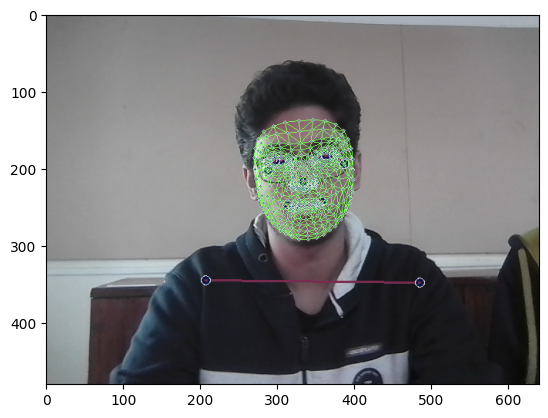

In [18]:
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)) # Last frame

# 3. Extracting Keypoints

In [20]:
def extract_keypoints(results):
    pose = np.array([[res.x, res.y, res.z, res.visibility] for res in results.pose_landmarks.landmark]).flatten() if results.pose_landmarks else np.zeros(33*4)
    face = np.array([[res.x, res.y, res.z] for res in results.face_landmarks.landmark]).flatten() if results.face_landmarks else np.zeros(468*3)
    lh = np.array([[res.x, res.y, res.z] for res in results.left_hand_landmarks.landmark]).flatten() if results.left_hand_landmarks else np.zeros(21*3)
    rh = np.array([[res.x, res.y, res.z] for res in results.right_hand_landmarks.landmark]).flatten() if results.right_hand_landmarks else np.zeros(21*3)
    return np.concatenate([pose, face, lh, rh])

# 4. Iterating over Videos and Storing Keypoints (Dataset Creation for Training)

## The WLASL video dataset is used here
## https://www.kaggle.com/datasets/waseemnagahhenes/sign-language-dataset-wlasl-videos

In [30]:
# Path to the main dataset folder
DATASET_PATH = os.path.join(os.getcwd(), "SL")
OUTPUT_PATH = os.path.join(os.getcwd(), "keypoints_output_final15")  # Creates "keypoints_output" in the same folder as "SL" and the Python code

# Create the output folder if it doesn't exist
if not os.path.exists(OUTPUT_PATH):
    os.makedirs(OUTPUT_PATH)

# For n number of frames/video

In [33]:
#sample = ['hello','name','here','yes','no','time','water','apple','brother','sister','book','love','again','and','basketball']
sample = ['hello','mother','father','name','potato','i','love','student','teacher','where','thank you','deaf','you','day','today']

In [35]:
# for subfolder in os.listdir(DATASET_PATH):
#     if subfolder in sample:
#         subfolder_path = os.path.join(DATASET_PATH, subfolder)
        
#         if not os.path.isdir(subfolder_path):
#             continue
        
#         output_subfolder = os.path.join(OUTPUT_PATH, subfolder)
#         if not os.path.exists(output_subfolder):
#             os.makedirs(output_subfolder)
    
#         video_count = 1
#         for video_file in os.listdir(subfolder_path):
#             video_path = os.path.join(subfolder_path, video_file)
            
#             if not video_file.endswith(".mp4"):
#                 continue
                
#             shortened_path = os.path.join(*video_path.split(os.sep)[-2:])
#             print(f"Processing: {shortened_path}")
#             cap = cv2.VideoCapture(video_path)
            
#             # Create a subfolder for the video in the output directory
#             video_output_folder = os.path.join(output_subfolder, str(video_count))#os.path.splitext(video_file)[0])
#             os.makedirs(video_output_folder, exist_ok=True)
    
#             j=0
#             with mp_holistic.Holistic(min_detection_confidence=0.75, min_tracking_confidence=0.75) as holistic:
#                 frame_count = 0
#                 while cap.isOpened() and frame_count < 2000:  # Limit to sequence_length = 30
#                     ret, frame = cap.read()
#                     if not ret:
#                         print("End of video or error reading frame")
#                         break
    
#                     # Make detections
#                     image, results = mediapipe_detection(frame, holistic)
    
#                     # Draw landmarks
#                     draw_styled_landmarks(image, results)
    
#                     # Show to screen
#                     cv2.imshow('Video', image)
    
#                     if (results.left_hand_landmarks is None or results.left_hand_landmarks.landmark is None) and (results.right_hand_landmarks is None or results.right_hand_landmarks.landmark is None):
#                         continue
                    
#                     # Extract keypoints
#                     keypoints = extract_keypoints(results)
                    
#                     # Save keypoints for the frame
#                     frame_output_path = os.path.join(video_output_folder, str(frame_count))
#                     np.save(frame_output_path, keypoints)
#                     j=j+1
                    
#                     frame_count += 1
    
#                     # Break gracefully
#                     if cv2.waitKey(10) & 0xFF == ord('q'):
#                         break
    
#             video_count+=1
            
#             cap.release()
#             cv2.destroyAllWindows()


# For 30 frames per video

In [38]:
actions = []
for subfolder in os.listdir(DATASET_PATH):
    if subfolder in sample:
        subfolder_path = os.path.join(DATASET_PATH, subfolder)
        
        if not os.path.isdir(subfolder_path):
            continue
    
        actions.append(subfolder)
        
        output_subfolder = os.path.join(OUTPUT_PATH, subfolder)
        if not os.path.exists(output_subfolder):
            os.makedirs(output_subfolder)
    
        video_count = 1
        for video_file in os.listdir(subfolder_path):
            video_path = os.path.join(subfolder_path, video_file)
            
            if not video_file.endswith(".mp4"):
                continue
                
            shortened_path = os.path.join(*video_path.split(os.sep)[-2:])
            print(f"Processing: {shortened_path}")
            cap = cv2.VideoCapture(video_path)
    
            # Get the total number of frames in the video
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            
            # Calculate the interval between frames to extract (if total_frames < 30, use all frames)
            interval = total_frames // 30 if total_frames >= 30 else total_frames
            
            # Create a subfolder for the video in the output directory
            video_output_folder = os.path.join(output_subfolder, str(video_count))
            os.makedirs(video_output_folder, exist_ok=True)
            
            j=0
            with mp_holistic.Holistic(min_detection_confidence=0.8, min_tracking_confidence=0.8) as holistic:
                for i in range(30):  # Extract 50 frames
                    frame_index = i * interval  # Calculate frame index
                    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)  # Set video to the desired frame
    
                    ret, frame = cap.read()
                    if not ret:
                        print(f"Error reading frame at index {frame_index}")
                        break
    
                    # Make detections
                    image, results = mediapipe_detection(frame, holistic)
    
                    # Draw landmarks
                    draw_styled_landmarks(image, results)
    
                    if (results.left_hand_landmarks is None or results.left_hand_landmarks.landmark is None) and (results.right_hand_landmarks is None or results.right_hand_landmarks.landmark is None):
                        continue
    
                    # Extract keypoints
                    keypoints = extract_keypoints(results)
                    
                    # Save keypoints for the frame
                    frame_output_path = os.path.join(video_output_folder, str(j))
                    np.save(frame_output_path, keypoints)
                    j = j+1
                    
                    # Optionally, display the frame (if needed)
                    cv2.imshow('Video', image)
                    
                    # Break gracefully
                    if cv2.waitKey(10) & 0xFF == ord('q'):
                        break
    
            video_count += 1
            cap.release()
            cv2.destroyAllWindows()


Processing: day\14792.mp4
Processing: day\14793.mp4
Processing: day\14794.mp4
Processing: day\14795.mp4
Processing: day\14796.mp4
Processing: day\14799.mp4
Processing: day\14803.mp4
Processing: day\65444.mp4
Processing: day\69291.mp4
Processing: deaf\14882.mp4
Processing: deaf\14883.mp4
Error reading frame at index 24
Processing: deaf\14884.mp4
Processing: deaf\14885.mp4
Error reading frame at index 26
Processing: deaf\14886.mp4
Processing: deaf\14887.mp4
Processing: deaf\14888.mp4
Processing: deaf\14893.mp4
Processing: deaf\14894.mp4
Processing: deaf\14903.mp4
Processing: deaf\65445.mp4
Processing: father\21204.mp4
Processing: father\21205.mp4
Processing: father\21207.mp4
Processing: father\21209.mp4
Processing: father\21212.mp4
Error reading frame at index 28
Processing: father\21221.mp4
Processing: father\69318.mp4
Processing: hello\27172.mp4
Processing: hello\27173.mp4
Processing: hello\27177.mp4
Processing: hello\27184.mp4
Processing: i\28789.mp4
Processing: i\28790.mp4
Processing

In [40]:
actions = os.listdir(OUTPUT_PATH)
print(actions)

['day', 'deaf', 'father', 'hello', 'i', 'love', 'mother', 'name', 'potato', 'student', 'teacher', 'thank you', 'today', 'where', 'you']


## Finding the length of each video in original dataset(debugging))

In [43]:
# import cv2
# import os

# def get_video_info(video_path):
#     video = cv2.VideoCapture(video_path)
#     if not video.isOpened():
#         return None, None  # Return None if the file cannot be opened
    
#     frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))  # Total number of frames
#     fps = video.get(cv2.CAP_PROP_FPS)  # Frames per second
#     video.release()
#     if fps > 0:
#         duration = frames / fps  # Duration in seconds
#         return duration, frames
#     return None, None  # Return None if FPS is invalid

# def find_video_info(directory):
#     video_info = {}
#     video_extensions = ('.mp4', '.avi', '.mov', '.mkv', '.wmv')  # Add extensions as needed
    
#     for root, _, files in os.walk(directory):
#         for file in files:
#             if file.lower().endswith(video_extensions):
#                 video_path = os.path.join(root, file)
#                 duration, frames = get_video_info(video_path)
#                 video_info[video_path] = (duration, frames)
    
#     return video_info

# # Example usage
# directory = DATASET_PATH  # Replace with your directory path
# video_info = find_video_info(directory)

# for video, (duration, frames) in video_info.items():
#     if duration is not None and frames is not None:
#         print(f"{video}: {duration:.4f} seconds, {frames} frames")
#         print(f" {frames/duration:.4f} fps")
#     else:
#         print(f"{video}: Could not determine length or frame count")


# 5. Preprocess Data and Create Labels and Features

In [46]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

In [48]:
label_map = {label:num for num, label in enumerate(actions)}

In [50]:
label_map

{'day': 0,
 'deaf': 1,
 'father': 2,
 'hello': 3,
 'i': 4,
 'love': 5,
 'mother': 6,
 'name': 7,
 'potato': 8,
 'student': 9,
 'teacher': 10,
 'thank you': 11,
 'today': 12,
 'where': 13,
 'you': 14}

In [52]:
sequences, labels = [], []
count = 0
count_ignored = 0
for action in actions:
    action_path = os.path.join(OUTPUT_PATH, action)
    count_action_ignored = 0
    #print(action_path)
    for sequence in np.array(os.listdir(action_path)).astype(int):
        number_vids = len(np.array(os.listdir(action_path)).astype(int))
        window = []
        sequence_path = os.path.join(action_path, str(sequence))
        #print(sequence_path)

        items = os.listdir(sequence_path)
        count = sum(1 for item in items if os.path.isfile(os.path.join(sequence_path, item)))
        #print(count)
        
        if count>1:
            for frame_num in range(count):
                npy_path = os.path.join(action_path, str(sequence), "{}.npy".format(frame_num))
                if os.path.isfile(npy_path):  
                    res = np.load(npy_path)
                    window.append(res)
                if os.path.isfile(npy_path)==False:
                    #print(f"Warning: {npy_path} not found.")
                    continue 
            if len(window) == count:  
                sequences.append(window)
                labels.append(label_map[action])
                #print(len(window))
        else:
            count_ignored += 1
            count_action_ignored += 1
            #print("Ignored: " + os.path.join(action_path, str(sequence)))
    if count_action_ignored>0:
        print(action + " = " + str(count_action_ignored) + ", Total videos = " + str(number_vids))

print(count_ignored)

deaf = 2, Total videos = 11
2


In [54]:
X = np.array(sequences, dtype = object)
print(X.shape)

(113,)


#### Data Augmetation: X

In [57]:
# noise = np.random.normal(0, 0.01, X.shape)
# noise = np.array(noise, dtype = object)
# noise = list(noise)

In [59]:
# X = list(X)
# X_len = len(X)

In [61]:
# for j in range(3):    
#     for i in range(X_len):
#         X.append(X[i])

In [63]:
# X = np.array(X, dtype = object)
# X.shape

## Padding X at the end for when irregular no. of frames are taken

In [66]:
# from tensorflow.keras.preprocessing.sequence import pad_sequences

# # Determine the maximum length of sequences
# max_length = max([np.array(sample).shape[0] for sample in X])

# # Pad sequences to have the same length
# X_padded = pad_sequences(
#     X, 
#     maxlen=max_length, 
#     padding='pre',  # Pad at the end of each sequence
#     dtype='float32'
# )

# print("Padded X shape:", X_padded.shape)
# print(np.array(X_padded[1]).shape)
# X=X_padded

## Padding X at the start and end for when irregular no. of frames are taken

In [69]:
# max_length = max([np.array(sample).shape[0] for sample in X])
# print(max_length)

In [71]:
# # Calculate padding amounts for each sequence
# def calculate_symmetric_padding(sequence, max_length):
#     current_length = len(sequence)
#     total_padding = max_length - current_length
#     pad_start = total_padding // 2
#     pad_end = total_padding - pad_start
#     return pad_start, pad_end

# # Apply symmetric padding
# padded_sequences = []
# for seq in X:
#     pad_start, pad_end = calculate_symmetric_padding(seq, max_length)
#     # First pad at the start
#     padded_seq = pad_sequences([seq], maxlen=len(seq) + pad_start, padding='pre', dtype='float32')[0]
#     # Then pad at the end
#     padded_seq = pad_sequences([padded_seq], maxlen=max_length, padding='post', dtype='float32')[0]
#     padded_sequences.append(padded_seq)

# # Convert to a numpy array
# X_padded = np.array(padded_sequences, dtype='float32')

# print("Padded X shape:", X_padded.shape)
# print("Example padded sequence:", X_padded[1])
# X = X_padded


# Interpolation with averages instead of padding

In [74]:
max_length = max([np.array(sample).shape[0] for sample in X])
print(max_length)

30


In [76]:
def average_interpolation(original_list, target_length):
    print(original_list)
    extended_list = original_list
    i=0
    while len(extended_list)<target_length:
        if i==len(extended_list)-1:
            i=0
        average = [(a+b)/2 for a,b in zip(original_list[i], original_list[i + 1])]
        #print(average)
        extended_list.insert(i+1, average)
        #print(extended_list)
        i+=2
    return extended_list

In [78]:
new_seq = []
for seq in X:
    #seq = np.array(seq)
    #print(len(seq))
    padded_seq = average_interpolation(seq, max_length)
    #print(len(padded_seq))
    new_seq.append(padded_seq)

[array([ 0.49510083,  0.22204521, -0.75721896, ...,  0.        ,
        0.        ,  0.        ]), array([ 0.49518529,  0.22171427, -0.48669451, ...,  0.36029875,
        0.3779749 , -0.02220672]), array([ 0.49609146,  0.22171532, -0.51150644, ...,  0.34422421,
        0.36125118, -0.00973417]), array([ 0.49698767,  0.22138399, -0.54416978, ...,  0.33078521,
        0.34283784, -0.01086646]), array([ 0.49945426,  0.21949884, -0.54436135, ...,  0.33945259,
        0.34562194, -0.01320452]), array([ 0.50056922,  0.21930511, -0.52659351, ...,  0.37197715,
        0.36303377, -0.01880734]), array([ 0.50053304,  0.21909264, -0.45883933, ...,  0.41481251,
        0.35818699,  0.00145601]), array([ 0.4996497 ,  0.2189222 , -0.44683728, ...,  0.46468174,
        0.35785961,  0.0059797 ]), array([ 0.49988571,  0.21888836, -0.4683587 , ...,  0.        ,
        0.        ,  0.        ]), array([ 0.50263888,  0.22325256, -0.45336661, ...,  0.53892612,
        0.58971769, -0.01307127]), array([ 0

In [79]:
X_padded = np.array(new_seq)
print(X_padded.shape)
X=X_padded

(113, 30, 1662)


In [88]:
np.array(labels).shape

(113,)

In [90]:
print(labels)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 7, 7, 7, 7, 7, 7, 8, 8, 8, 8, 8, 8, 8, 8, 9, 9, 9, 9, 9, 9, 9, 9, 10, 10, 10, 10, 10, 10, 10, 10, 11, 11, 11, 11, 11, 11, 11, 12, 12, 12, 12, 12, 12, 12, 12, 12, 13, 13, 13, 13, 13, 13, 13, 14, 14, 14, 14, 14, 14, 14, 14]


In [92]:
y = to_categorical(labels).astype(int)

#### Data Augmentation: Labels

In [95]:
# y = list(y)
# y_len=len(y)
# for j in range(3):    
#     for i in range(y_len):
#         y.append(y[i])
# y = np.array(y)
# y.shape

## Train-Test Splitting

In [98]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.0001, shuffle = True)

In [100]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(112, 30, 1662)
(1, 30, 1662)
(112, 15)
(1, 15)


In [102]:
y

array([[1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       [1, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1]])

# 6. Build and Train LSTM Neural Network

In [105]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Masking, Bidirectional, LeakyReLU, Input
from tensorflow.keras.callbacks import TensorBoard

In [107]:
log_dir = os.path.join('Logs')
tb_callback = TensorBoard(log_dir=log_dir)

In [109]:
del model

NameError: name 'model' is not defined

In [111]:
model = Sequential()
#model.add(Masking(mask_value=0.0, input_shape=(max_length, 1662)))
model.add(Input(shape=(max_length, 1662)))
model.add(LSTM(128, return_sequences=True))
model.add(Bidirectional(LSTM(256, return_sequences=True)))
model.add(LeakyReLU(negative_slope=0.2))
model.add(LSTM(128, return_sequences=False))
model.add(LeakyReLU(negative_slope=0.2))
model.add(Dense(512))
model.add(LeakyReLU(negative_slope=0.2))
model.add(Dense(256))
model.add(LeakyReLU(negative_slope=0.2))
model.add(Dense(np.array(actions).shape[0], activation='softmax'))

In [113]:
# from tensorflow.keras.callbacks import EarlyStopping

# # Define EarlyStopping
# early_stopping = EarlyStopping(
#     monitor='categorical_accuracy',
#     patience=10,
#     restore_best_weights=True,
#     min_delta = 0.1
# )

In [115]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['categorical_accuracy'])

In [117]:
model.fit(X_train, y_train, epochs=200,
    callbacks=[tb_callback])

Epoch 1/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - categorical_accuracy: 0.0869 - loss: 2.7108
Epoch 2/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - categorical_accuracy: 0.1070 - loss: 2.6988
Epoch 3/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - categorical_accuracy: 0.1030 - loss: 2.6860
Epoch 4/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - categorical_accuracy: 0.1714 - loss: 2.6727
Epoch 5/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - categorical_accuracy: 0.1777 - loss: 2.6499
Epoch 6/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - categorical_accuracy: 0.1887 - loss: 2.6116
Epoch 7/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - categorical_accuracy: 0.1991 - loss: 2.5611
Epoch 8/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - categorical_accuracy: 0.1679 - loss: 2.5115
Epoch 9/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - categorical_accuracy: 0.1829 - loss: 2.4369
Epoch 10/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - categorical_accuracy: 0.2351 - loss: 2.3684
Epoch 11/200
4/4 ━━━━━━━━━━━━━━━━━━━━ 0

#### Transformer (attempt)

In [119]:
# import tensorflow as tf
# from tensorflow.keras import layers, models

# # Parameters
# input_shape = (30, 1662)  # 30 frames, 1662 keypoints per frame
# num_classes = 12  # 12 sign language words
# embed_dim = 512  # Embedding dimension for transformer
# num_heads = 8  # Number of attention heads
# num_layers = 4  # Number of transformer layers
# dropout_rate = 0.1  # Dropout rate

# # Build the Transformer model
# def build_transformer_model(input_shape, num_classes, embed_dim, num_heads, num_layers, dropout_rate):
#     inputs = layers.Input(shape=input_shape)

#     # Apply a Conv1D layer to extract features from the keypoints for each frame (frame-wise feature extraction)
#     x = layers.Conv1D(filters=embed_dim, kernel_size=3, activation='relu', padding='same')(inputs)  # Shape: (batch_size, 30, embed_dim)
#     x = layers.MaxPooling1D(pool_size=2)(x)  # Downsample the frame features, Shape: (batch_size, 15, embed_dim)

#     # Apply a Transformer Encoder
#     for _ in range(num_layers):
#         # Multi-Head Attention
#         attention_output = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)(x, x)
#         attention_output = layers.Dropout(dropout_rate)(attention_output)
#         x = layers.Add()([x, attention_output])  # Skip connection
#         x = layers.LayerNormalization()(x)

#         # Feed Forward Network
#         ffn_output = layers.Dense(embed_dim * 4, activation='relu')(x)
#         ffn_output = layers.Dense(embed_dim)(ffn_output)
#         ffn_output = layers.Dropout(dropout_rate)(ffn_output)
#         x = layers.Add()([x, ffn_output])  # Skip connection
#         x = layers.LayerNormalization()(x)

#     # Global Average Pooling
#     x = layers.GlobalAveragePooling1D()(x)  # Pool the sequence to a fixed-size vector

#     # Fully Connected Layer
#     x = layers.Dense(128, activation='relu')(x)
#     x = layers.Dropout(0.5)(x)

#     # Output Layer
#     outputs = layers.Dense(num_classes, activation='softmax')(x)

#     # Model
#     model = models.Model(inputs, outputs)
#     return model

# # Build and compile the model
# model = build_transformer_model(input_shape, num_classes, embed_dim, num_heads, num_layers, dropout_rate)
# model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['categorical_accuracy'])

# # Model summary
# model.summary()


In [121]:
# # Train the model
# history = model.fit(X_train, y_train, epochs=100, batch_size=16, validation_split=0.2)

# 8. Make Predictions

In [124]:
res = model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 421ms/step


In [126]:
for i in range (len(X_test)):
    print(actions[np.argmax(res[i])] + ', ' + actions[np.argmax(y_test[i])])

potato, today


# 9. Save Weights

In [129]:
# model.save('action_38_300.keras')

# 10. Evaluation using Confusion Matrix and Accuracy

In [132]:
np.sum(res[0])

1.0000001

In [134]:
from sklearn.metrics import multilabel_confusion_matrix, accuracy_score

In [136]:
yhat = model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


In [138]:
ytrue = np.argmax(y_test, axis=1).tolist()
yhat = np.argmax(yhat, axis=1).tolist()

In [140]:
multilabel_confusion_matrix(ytrue, yhat)

array([[[0., 1.],
        [0., 0.]],

       [[0., 0.],
        [1., 0.]]])

In [142]:
accuracy_score(ytrue, yhat)

0.0

# 11. Test in Real Time

In [145]:
from scipy import stats

# ASL Gloss to English translation

## Loading the Translation Model

In [153]:
from transformers import T5ForConditionalGeneration, T5Tokenizer

# Load the model and tokenizer
translator_model = T5ForConditionalGeneration.from_pretrained("fine_tuned_model")
tokenizer = T5Tokenizer.from_pretrained("fine_tuned_model")

In [155]:
def translate_asl(asl_sentence):
    translator_model.eval()
    input_ids = tokenizer(f"translate ASL to English: {asl_sentence}", return_tensors="pt").input_ids
    outputs = translator_model.generate(input_ids)
    translated_sentence = tokenizer.decode(outputs[0], skip_special_tokens=True)
    return translated_sentence

In [157]:
def is_question(sentence):
    # List of common question words
    question_words = ['what', 'how', 'why', 'where', 'who', 'when', 'is', 'are', 'can', 'could', 'will', 'do', 'does']
    
    # Split the sentence into words
    words = sentence.split()
    
    # Check if the list contains any question word or if the last word is 'you'
    if any(word.lower() in question_words for word in words) or words[-1].lower() == 'you' or words[-1].lower() == 'name':
        return True
    return False

def add_question_mark(sentence):
    # Check if the sentence is a question
    if is_question(sentence):
        # Ensure the sentence ends with a question mark
        if not sentence.endswith('?'):
            sentence += '?'
    words = sentence.split()
    print(words)
    count =0
    for i in words:
        if len(i)==1:
            count+=1
    print(count)
    print(len(words))
    if count==len(words):
        
        sentence = sentence.replace(" ", "")
    return sentence

In [174]:
################################## with counter updation and next word prediction 

sequence = []
sentence = []
test_sentence = []
predictions = []
threshold = 0.75
frame_counter = 0  # Counter for frames collected
prediction_done = False  # Flag to indicate that a word has been predicted
current_word = ""  # To store the current word being predicted
test_sentence = []

cap = cv2.VideoCapture(0)
mp_holistic = mp.solutions.holistic

# Initialize Mediapipe model
with mp_holistic.Holistic(min_detection_confidence=0.8, min_tracking_confidence=0.8) as holistic:
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        # Make detections
        image, results = mediapipe_detection(frame, holistic)

        # Draw landmarks
        draw_styled_landmarks(image, results)

        if results.left_hand_landmarks or results.right_hand_landmarks:
            # Indicate that the system is recording an ASL action
            cv2.putText(image, "Recording ASL Action...", (125, 80), cv2.FONT_HERSHEY_COMPLEX, 1, (255, 0, 0), 2, cv2.LINE_AA)

            # Collect keypoints for 30 frames
            keypoints = extract_keypoints(results)
            sequence.append(keypoints)
            sequence = sequence[-30:]  # Keep only the last 30 frames

            # Update frame counter
            frame_counter = len(sequence)

            if len(sequence) == 30:
                # Predict the action
                res = model.predict(np.expand_dims(sequence, axis=0))[0]
                predictions.append(np.argmax(res))

                if np.unique(predictions[-10:])[0] == np.argmax(res) and res[np.argmax(res)] > threshold:
                    if not sentence or actions[np.argmax(res)] != sentence[-1]:
                        sentence.append(actions[np.argmax(res)])
                        test_sentence.append(actions[np.argmax(res)])
                        current_word = actions[np.argmax(res)]  # Store current predicted word
                        #prediction_done = True  # Indicate that prediction is done
                        #####remove till current word
                        frame_counter = 0
                        sequence = []  
                        #prediction_done = False  # Reset the prediction done flag
                        # current_word = "" 


                if len(sentence) > 5:
                    sentence = sentence[-5:]

        else:
            # Indicate that the system is ready for the next action
            cv2.putText(image, "Waiting for the next sign", (100, 80), cv2.FONT_HERSHEY_COMPLEX, 1, (0, 0, 255), 2, cv2.LINE_AA)

            # Reset frame counter and clear the sequence when waiting for the next sign
            frame_counter = 0
            sequence = []  
            #prediction_done = False  # Reset the prediction done flag
            # current_word = ""  # Reset the current word

        # Display frame counter in the bottom-right corner
        height, width, _ = image.shape
        cv2.putText(image, "Frame Count:", (width - 200, height - 50), cv2.FONT_HERSHEY_COMPLEX, 0.8, (0, 255, 0), 2, cv2.LINE_AA)
        cv2.putText(image, f"{frame_counter}/30", (width - 150, height - 20), cv2.FONT_HERSHEY_COMPLEX, 0.8, (0, 255, 0), 2, cv2.LINE_AA)
        
        # After prediction is done, change message to "Prediction Done for (word)"
        cv2.putText(image, f"Prediction Done for: {current_word}", (10, height - 40), cv2.FONT_HERSHEY_COMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
            
        cv2.putText(image, "Predicting next word now...", (10, height - 20), cv2.FONT_HERSHEY_COMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)

        # Display sentence and visualization
        cv2.rectangle(image, (0, 0), (640, 40), (0, 0, 255), -1)  # Red rectangle for sentence display
        cv2.putText(image, ' '.join(sentence), (10, 30), cv2.FONT_HERSHEY_COMPLEX, 1, (255, 255, 255), 2, cv2.LINE_AA)

        # Show the frame
        cv2.imshow('ASL Detection', image)

        # Break gracefully
        if cv2.waitKey(10) & 0xFF == ord('q'):
            break

cap.release()
cv2.destroyAllWindows()

updated_test_sentence=add_question_mark(' '.join(test_sentence))
translation = translate_asl(updated_test_sentence)
print("ASL Gloss:", updated_test_sentence)
print("English Translation:", translation)

IndexError: list index out of range

In [162]:
print(actions)

['day', 'deaf', 'father', 'hello', 'i', 'love', 'mother', 'name', 'potato', 'student', 'teacher', 'thank you', 'today', 'where', 'you']
